In [1]:
from quantify_core.data.handling import (
    default_datadir,
    get_latest_tuid,
    get_tuids_containing,
    load_dataset,
    locate_experiment_container,
    set_datadir,
)

import numpy as np
import matplotlib.pyplot as plt

from collections import OrderedDict

import deprecated
import matplotlib.pyplot as plt
import numpy as np
from pyDOE2 import lhs
import itertools
from numpy.typing import NDArray
import xarray as xr
from cmaes import CMA, get_warm_start_mgd
from typing import Tuple, Callable, List, Any, Optional, Dict
from qcodes import Parameter, validators
from quantify_core.measurement.control import MeasurementControl
from quantify_core.measurement.types import Settable, Gettable
from quantify_core.analysis.base_analysis import BaseAnalysis, BasicAnalysis
from quantify_core.visualization.mpl_plotting import set_suptitle_from_dataset
from quantify_core.data.handling import trim_dataset
from quantify_scheduler import Schedule
from quantify_scheduler.enums import BinMode

from quantify_core.analysis.base_analysis import Basic2DAnalysis
from quantify_core.data.handling import to_gridded_dataset, grow_dataset
from qce_utils.support_classes.utilities_array_shaping import (
    pairwise_complex,
    normalize_tensor_dataset,
    recursively_split_and_process_dataset,
)
from qce_utils.addon_quantify.decorator_metadata import metadata_from_function_signature
from qce_utils.addon_quantify.deserialize_xarray_to_obj import (
    DeserializeBootstrap,
    IXarrayBootstrap,
)

from qce_utils.qed_modeling.intrf_state_classification import (
    IQNDPiStateClassifierContainer,
)
from qce_utils.addon_quantify.object_factories.factory_state_acquisition import (
    QNDPiStateClassifierFactory,
    QNDPiStateClassifierContainer,
    QNDPiLandscapeFactory,
    MultiQubitQNDPiStateClassifierFactory,
    MultiQubitQNDPiStateClassifierContainer,
    AcquisitionType,
    MultiQubitQNDPiOptimizationFactory,
    StateKey,
)
from qce_utils.control_interfaces.datastorage_control.analysis_factories.factory_state_classification import (
    StateAxesProjectionAnalysis,
    QNDPiStateClassifierAnalysis,
    QNDPiLandscapeContainer,
    QNDPiLandscapeAnalysis,
    QNDPiAndSNRLandscapeAnalysis,
    LandscapeType,
    FigureContainer,
    QNDPiOptimizationAnalysis,
    MultiQubitReadoutOptimizationContainer,
    IReadoutOptimizationContainer,
    OptimizedReadoutParameters,
)
from qce_interp.interface_definitions.intrf_state_classification import (
    StateBoundaryKey,
    StateKey,
)
from qce_utils.addon_quantify.object_factories.factory_readout_transient import (
    OptimalWeightsFactory,
)
from qce_utils.control_interfaces.datastorage_control.analysis_factories.factory_readout_transient import (
    OptimalWeightsIdentifier,
    ReadoutTransientAnalysis,
    OptimalWeightsAnalysis as OptimalWeightsAnalysis_,
)
# from hqt_utils.operations.gate_library import Identity

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import colorsys

In [2]:
set_datadir(default_datadir())

Data will be saved in:
/home/pschaefers/quantify-data


In [24]:
def process_CMAES_data(dataset, population_size, qubit_names=None):
    """
    Processes fidelity data for n qubits based on the given dataset and population size.

    Parameters:
        dataset: An object containing data attributes (e.g., dataset.x0.data, dataset.y0.data, etc.).
        population_size: The size of the population.
        nr_qubits: The number of qubits.

    Returns:
        A dictionary containing mean and population fidelity data for all qubit_names and shared parameters.
    """

    if qubit_names is None:
        if hasattr(dataset, "elements"):
            qubit_names = dataset.elements
        else:
            raise ValueError("No qubit names provided and dataset has no 'elements' attribute.")

    # Initialize dictionary to hold data for each qubit
    fidelity_data = {}

    name_to_var = {dataset[var].attrs.get("name"): var for var in dataset.data_vars}
    name_to_coord = {dataset[coord].attrs.get("name"): coord for coord in dataset.coords}
        
    for qubit in qubit_names:
        # Extract fidelity data for the current qubit
        fidelity_data[qubit] = {
            'freq': dataset[name_to_coord.get(f"frequency_{qubit}")].values,
            'ampl': dataset[name_to_coord.get(f"amplitude_{qubit}")].values,
            'dur': dataset[name_to_coord.get(f"duration_{qubit}")].values,
            'objective': dataset[name_to_var.get(f"objective{qubit}")].values,
            'assignfid_av': dataset[name_to_var.get(f"av_assignment_{qubit}")].values,
            'assignfid_01': dataset[name_to_var.get(f"01_assignment_{qubit}")].values,
            'assignfid_02': dataset[name_to_var.get(f"02_assignment_{qubit}")].values,
            'assignfid_12': dataset[name_to_var.get(f"12_assignment_{qubit}")].values,
            'qndpifid': dataset[name_to_var.get(f"qnd_pi_{qubit}")].values,
        }

        # Extract data of the mean
        fidelity_data[qubit]['mean'] = {
            key: fidelity_data[qubit][key][population_size::population_size + 1]
            for key in
            ['freq', 'ampl', 'dur','objective', 'assignfid_av', 'assignfid_01', 'assignfid_02', 'assignfid_12', 'qndpifid']
        }

        # Extract data of the population
        fidelity_data[qubit]['pop'] = {
            key: np.array([
                fidelity_data[qubit][key][i::population_size + 1]
                for i in range(population_size)
            ])
            for key in
            ['freq', 'ampl', 'dur','objective', 'assignfid_av', 'assignfid_01', 'assignfid_02', 'assignfid_12', 'qndpifid']
        }

    return fidelity_data

In [25]:
nr_population_size = 60
nr_generations = 150

tuid_ws = "20250923-015508-130-b402be"
dataset_ws = load_dataset(tuid=tuid_ws)
qubit_names_ws = dataset_ws.elements
data_ws = process_CMAES_data(dataset_ws,nr_population_size)

tuid = "20250911-163302-486-9dc2e5"
dataset = load_dataset(tuid=tuid)
qubit_names = dataset.elements
data = process_CMAES_data(dataset,nr_population_size)

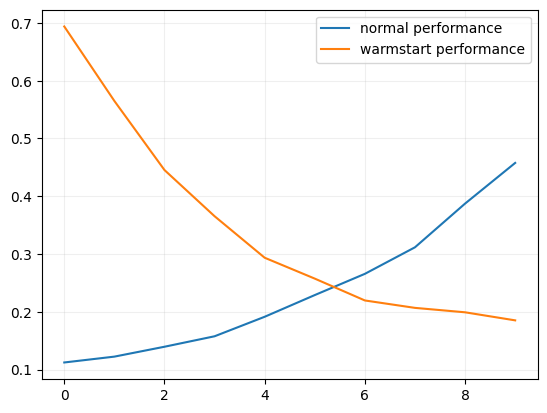

In [139]:
average_ws_performance = []
average_performance = []

for i in range(10):
    ws_performance = []
    performance = []
    
    for qubit in qubit_names_ws:
        ffreq_ws = data_ws[qubit]['mean']['freq'][0+i]/data_ws[qubit]['mean']['freq'][138+i]
        fampl_ws = data_ws[qubit]['mean']['ampl'][0+i]/data_ws[qubit]['mean']['ampl'][138+i]
        fdur_ws = data_ws[qubit]['mean']['dur'][0+i]/data_ws[qubit]['mean']['dur'][138+i]
    
        ws_farr = np.array([ffreq_ws, fampl_ws, fdur_ws])
        ws_performance.append(np.linalg.norm(ws_farr-np.ones(3)))
    
        ffreq = data[qubit]['mean']['freq'][10-i]/data[qubit]['mean']['freq'][149-i]
        fampl = data[qubit]['mean']['ampl'][10-i]/data[qubit]['mean']['ampl'][149-i]
        fdur = data[qubit]['mean']['dur'][10-i]/data[qubit]['mean']['dur'][149-i]
    
        farr = np.array([ffreq, fampl, fdur])
        performance.append(np.linalg.norm(farr-np.ones(3)))

    average_performance.append(np.mean(np.array(performance)))
    average_ws_performance.append(np.mean(np.array(ws_performance)))
    

plt.plot(range(10), average_performance, label="normal performance")
plt.plot(range(10), average_ws_performance, label="warmstart performance")
plt.grid(alpha=.2)
plt.legend()
plt.show()

# plt.plot(qubit_names_ws,ws_performance, label="warmstart performance")
# plt.plot(qubit_names_ws,performance, label="normal performance")
# plt.grid(alpha=.2)
# plt.legend()
# plt.show()
    

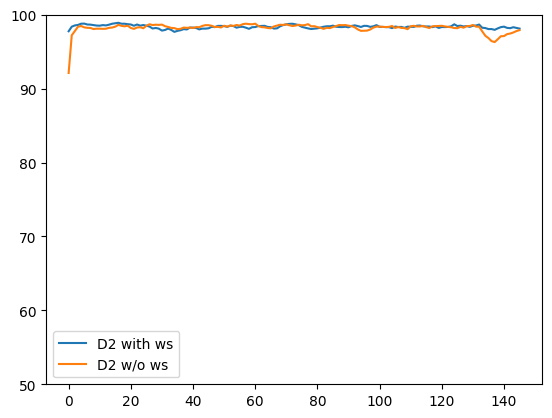

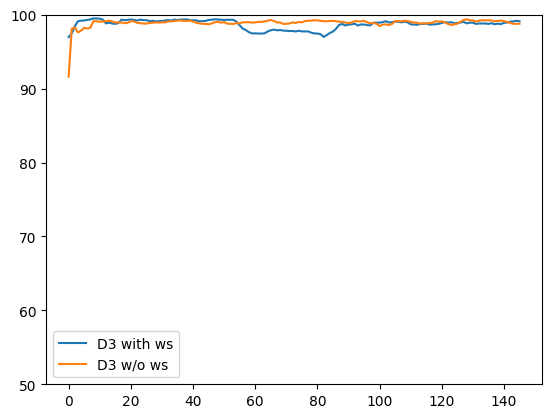

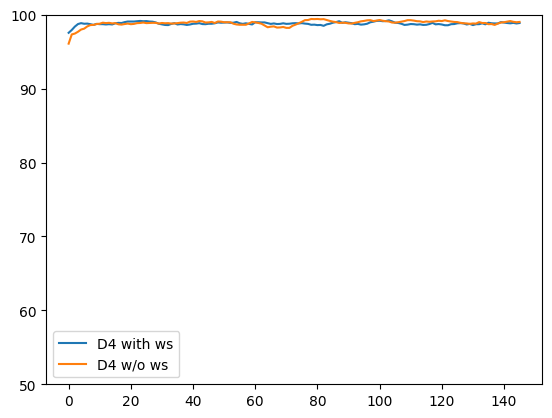

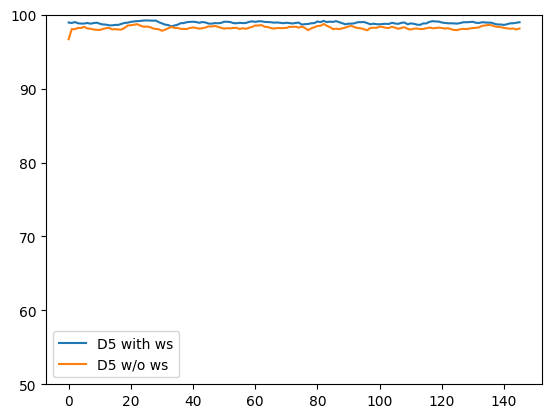

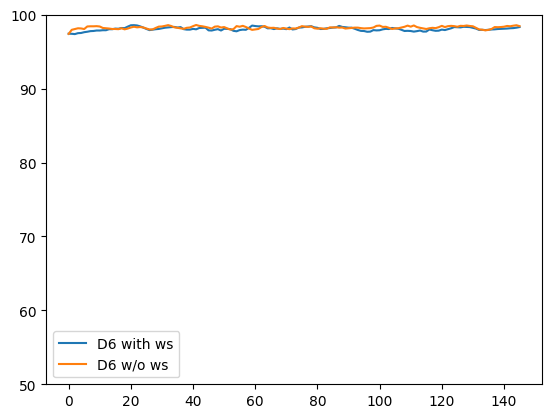

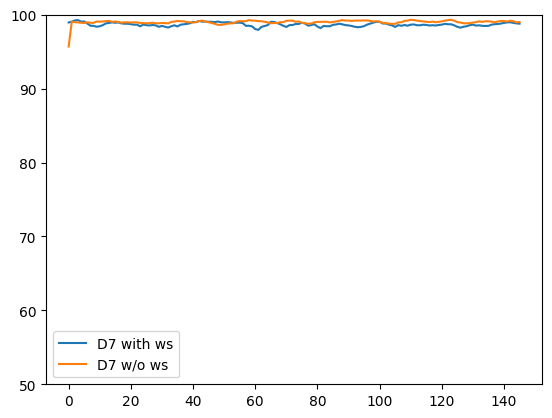

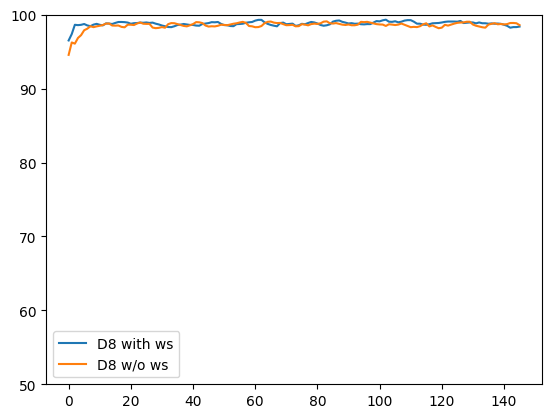

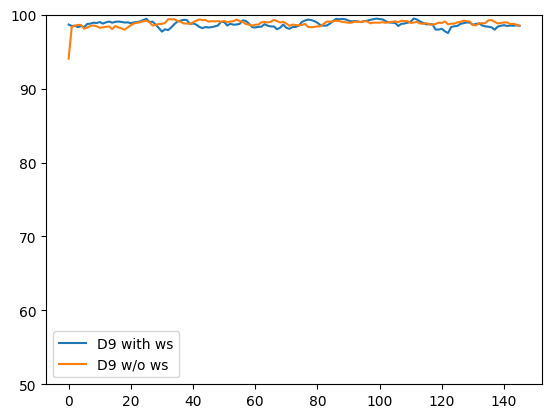

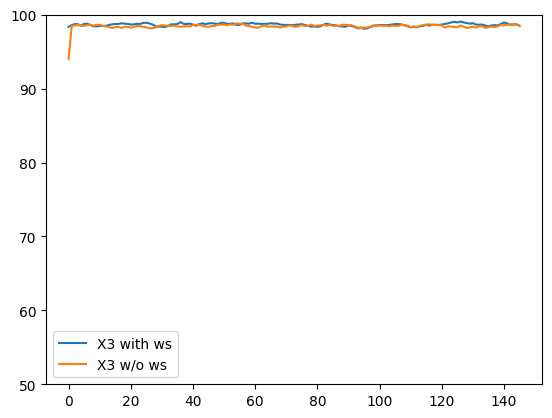

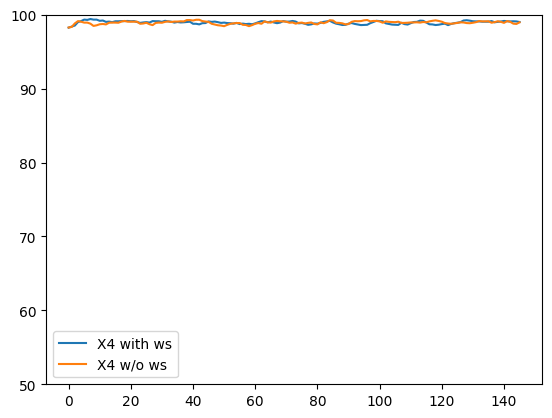

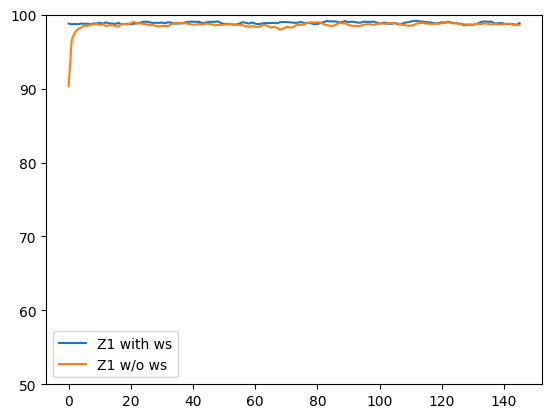

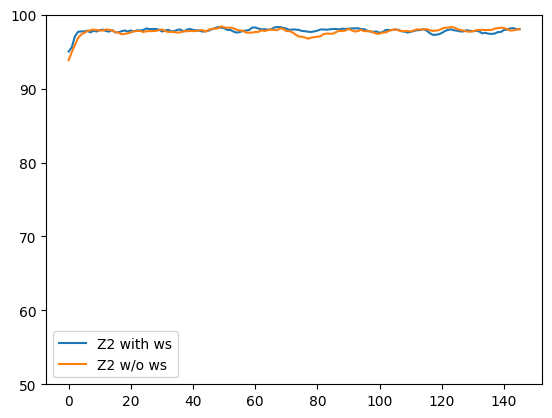

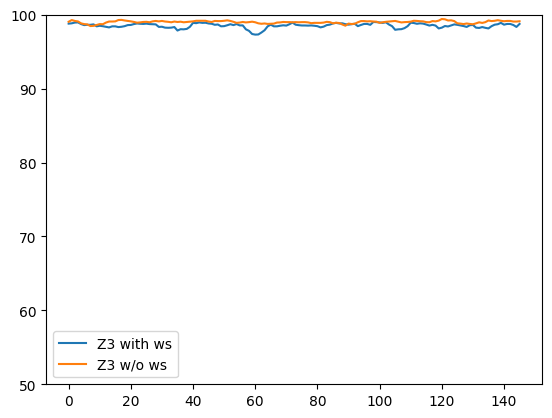

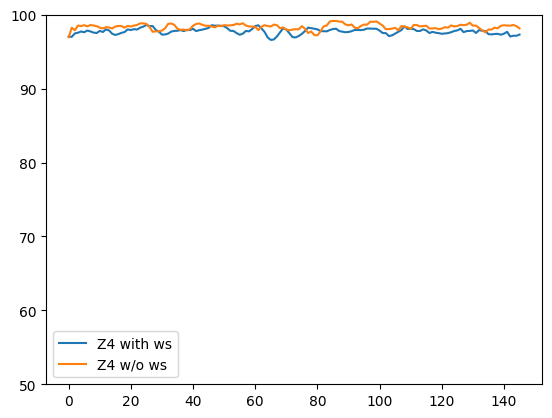

In [55]:
N_window = 5

for qubit in qubit_names_ws:
    obj_ws = data_ws[qubit]['mean']['assignfid_01']
    moving_std_ws = [np.mean(obj_ws[i:i+N_window])*100 for i in range(len(obj_ws)-N_window+1)]
    label = qubit + " with ws"
    plt.plot(moving_std_ws, label = label)

    obj = data[qubit]['mean']['assignfid_01']
    moving_std = [np.mean(obj[i:i+N_window])*100 for i in range(len(obj)-N_window+1)]
    label = qubit + " w/o ws"
    plt.plot(moving_std, label = label)

    plt.ylim(50,100)
    plt.legend()
    plt.show()

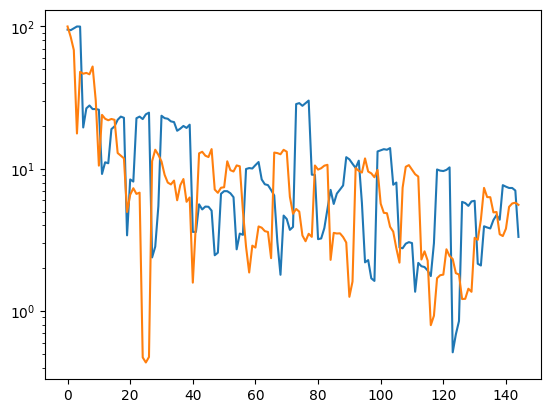

In [112]:
N_steps = 5

for qubit in [qubit_names_ws[0]]:
    diff_freq = np.diff(data_ws[qubit]['mean']['freq'])
    diff_ampl = np.diff(data_ws[qubit]['mean']['ampl'])
    diff_dur = np.diff(data_ws[qubit]['mean']['dur'])
    objective = data_ws[qubit]['mean']['objective'][1:] #ignore initial objective value  
    
    vector = np.array([diff_freq, diff_ampl, diff_dur]).T
    norm = np.linalg.norm(vector, axis=1)

    scaled_objective = norm*(objective-np.min(objective))
    rolling_mean_scaled_objective = np.array([np.std(scaled_objective[i:i+N_steps]) for i in range(len(scaled_objective)-N_steps+1)])

    plt.plot(rolling_mean_scaled_objective/np.max(rolling_mean_scaled_objective)*100)

    diff_freq = np.diff(data[qubit]['mean']['freq'])
    diff_ampl = np.diff(data[qubit]['mean']['ampl'])
    diff_dur = np.diff(data[qubit]['mean']['dur'])
    objective = data[qubit]['mean']['objective'][1:] #ignore initial objective value  
    
    vector = np.array([diff_freq, diff_ampl, diff_dur]).T
    norm = np.linalg.norm(vector, axis=1)

    scaled_objective = norm*(objective-np.min(objective))
    rolling_mean_scaled_objective = np.array([np.std(scaled_objective[i:i+N_steps]) for i in range(len(scaled_objective)-N_steps+1)])
    

    plt.plot(rolling_mean_scaled_objective/np.max(rolling_mean_scaled_objective)*100)

plt.yscale('log')
plt.show()

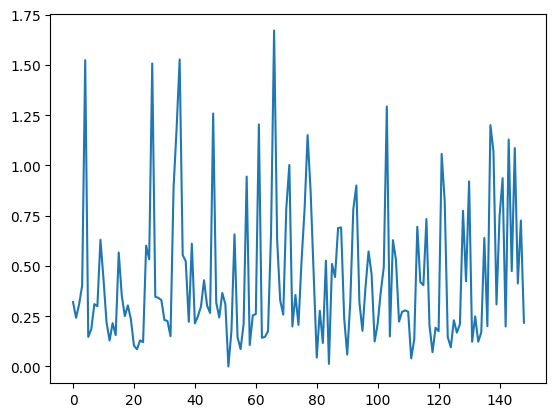

In [90]:
plt.plot(objective-np.min(objective))
plt.show()

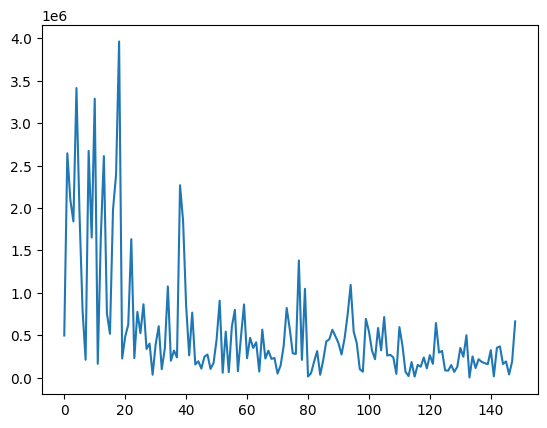

In [91]:
plt.plot(norm)